# AlphaMissense · Opus R2 · AlphaFold residue confidence

Run all cells in order. This notebook downloads the public inputs, computes the axis and performance, draws the controls, and evaluates the decision. All analysis code is contained below.

Python 3.11; packages: `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 biopython==1.85 pyhmmer==0.12.1`. Install these into the notebook kernel environment before running.


## 1. Data source / acquisition

The fixed panel contains 73 ProteinGym assays of 64 human proteins. Assay identifiers and accessions below define the selection independently of outcomes. ProteinGym v1.3 provides experimental measurements and the pinned metadata commit provides target sequences and alignment metadata. AlphaMissense provides its published amino-acid substitution scores. Downloaded files are checked by size and SHA-256 before reuse.

The public reference bundle supplies pinned Swiss-Prot canonical sequences for mapping assay-local positions to full-protein score positions. Residue analyses also use the selected raw ProteinGym alignments or AlphaFold structure files. Only the specified raw members are extracted. The data providers are [UniProt](https://www.uniprot.org/), [ProteinGym](https://proteingym.org/), and [AlphaFold DB](https://alphafold.ebi.ac.uk/).


In [1]:
ANALYSIS_ID='am-opus-r2/test-01'
RUN=2
AXIS=1
SOURCES={'metadata': {'filename': 'DMS_substitutions.csv',
              'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
              'bytes': 208734,
              'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308'},
 'experiments': {'filename': 'DMS_ProteinGym_v1.3_substitutions.zip',
                 'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
                 'bytes': 43021128,
                 'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921'},
 'scores': {'filename': 'AlphaMissense_aa_substitutions.tsv.gz',
            'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
            'bytes': 1207278510,
            'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d'},
 'reference_bundle': {'filename': 'alphamissense-inputs.zip',
                      'url': 'https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/alphamissense-inputs.zip',
                      'bytes': 998791045,
                      'sha256': '9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c'}}
PANEL=[{'assay': 'A4_HUMAN_Seuma_2022', 'acc': 'P05067'},
 {'assay': 'ACE2_HUMAN_Chan_2020', 'acc': 'Q9BYF1'},
 {'assay': 'ADRB2_HUMAN_Jones_2020', 'acc': 'P07550'},
 {'assay': 'AICDA_HUMAN_Gajula_2014_3cycles', 'acc': 'Q9GZX7'},
 {'assay': 'B2L11_HUMAN_Dutta_2010_binding-Mcl-1', 'acc': 'O43521'},
 {'assay': 'BRCA1_HUMAN_Findlay_2018', 'acc': 'P38398'},
 {'assay': 'BRCA2_HUMAN_Erwood_2022_HEK293T', 'acc': 'P51587'},
 {'assay': 'CALM1_HUMAN_Weile_2017', 'acc': 'P0DP23'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_gof', 'acc': 'Q9BXL7'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_lof', 'acc': 'Q9BXL7'},
 {'assay': 'CBPA2_HUMAN_Tsuboyama_2023_1O6X', 'acc': 'P48052'},
 {'assay': 'CBS_HUMAN_Sun_2020', 'acc': 'P35520'},
 {'assay': 'CBX4_HUMAN_Tsuboyama_2023_2K28', 'acc': 'O00257'},
 {'assay': 'CCR5_HUMAN_Gill_2023', 'acc': 'P51681'},
 {'assay': 'CD19_HUMAN_Klesmith_2019_FMC_singles', 'acc': 'P15391'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_abundance', 'acc': 'P11712'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_activity', 'acc': 'P11712'},
 {'assay': 'DLG4_HUMAN_Faure_2021', 'acc': 'P78352'},
 {'assay': 'DNJA1_HUMAN_Tsuboyama_2023_2LO1', 'acc': 'P31689'},
 {'assay': 'EPHB2_HUMAN_Tsuboyama_2023_1F0M', 'acc': 'P29323'},
 {'assay': 'ERBB2_HUMAN_Elazar_2016', 'acc': 'P04626'},
 {'assay': 'FKBP3_HUMAN_Tsuboyama_2023_2KFV', 'acc': 'Q00688'},
 {'assay': 'GDIA_HUMAN_Silverstein_2021', 'acc': 'P31150'},
 {'assay': 'GRB2_HUMAN_Faure_2021', 'acc': 'P62993'},
 {'assay': 'HEM3_HUMAN_Loggerenberg_2023', 'acc': 'P08397'},
 {'assay': 'HMDH_HUMAN_Jiang_2019', 'acc': 'P04035'},
 {'assay': 'HXK4_HUMAN_Gersing_2022_activity', 'acc': 'P35557'},
 {'assay': 'HXK4_HUMAN_Gersing_2023_abundance', 'acc': 'P35557'},
 {'assay': 'KCNH2_HUMAN_Kozek_2020', 'acc': 'Q12809'},
 {'assay': 'LYAM1_HUMAN_Elazar_2016', 'acc': 'P14151'},
 {'assay': 'MET_HUMAN_Estevam_2023', 'acc': 'P08581'},
 {'assay': 'MK01_HUMAN_Brenan_2016', 'acc': 'P28482'},
 {'assay': 'MSH2_HUMAN_Jia_2020', 'acc': 'P43246'},
 {'assay': 'MTHR_HUMAN_Weile_2021', 'acc': 'P42898'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_HEK293T', 'acc': 'O15118'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_RPE1', 'acc': 'O15118'},
 {'assay': 'NUD15_HUMAN_Suiter_2020', 'acc': 'Q9NV35'},
 {'assay': 'OBSCN_HUMAN_Tsuboyama_2023_1V1C', 'acc': 'Q5VST9'},
 {'assay': 'OPSD_HUMAN_Wan_2019', 'acc': 'P08100'},
 {'assay': 'OTC_HUMAN_Lo_2023', 'acc': 'P00480'},
 {'assay': 'OTU7A_HUMAN_Tsuboyama_2023_2L2D', 'acc': 'Q8TE49'},
 {'assay': 'P53_HUMAN_Kotler_2018', 'acc': 'P04637'},
 {'assay': 'PAI1_HUMAN_Huttinger_2021', 'acc': 'P05121'},
 {'assay': 'PIN1_HUMAN_Tsuboyama_2023_1I6C', 'acc': 'Q13526'},
 {'assay': 'PPARG_HUMAN_Majithia_2016', 'acc': 'P37231'},
 {'assay': 'PPM1D_HUMAN_Miller_2022', 'acc': 'O15297'},
 {'assay': 'PR40A_HUMAN_Tsuboyama_2023_1UZC', 'acc': 'O75400'},
 {'assay': 'PRKN_HUMAN_Clausen_2023', 'acc': 'O60260'},
 {'assay': 'PTEN_HUMAN_Matreyek_2021', 'acc': 'P60484'},
 {'assay': 'PTEN_HUMAN_Mighell_2018', 'acc': 'P60484'},
 {'assay': 'RAF1_HUMAN_Zinkus-Boltz_2019', 'acc': 'P04049'},
 {'assay': 'RASH_HUMAN_Bandaru_2017', 'acc': 'P01112'},
 {'assay': 'RD23A_HUMAN_Tsuboyama_2023_1IFY', 'acc': 'P54725'},
 {'assay': 'S22A1_HUMAN_Yee_2023_abundance', 'acc': 'O15245'},
 {'assay': 'S22A1_HUMAN_Yee_2023_activity', 'acc': 'O15245'},
 {'assay': 'SC6A4_HUMAN_Young_2021', 'acc': 'P31645'},
 {'assay': 'SCN5A_HUMAN_Glazer_2019', 'acc': 'Q14524'},
 {'assay': 'SERC_HUMAN_Xie_2023', 'acc': 'Q9Y617'},
 {'assay': 'SHOC2_HUMAN_Kwon_2022', 'acc': 'Q9UQ13'},
 {'assay': 'SOX30_HUMAN_Tsuboyama_2023_7JJK', 'acc': 'O94993'},
 {'assay': 'SRC_HUMAN_Ahler_2019', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Chakraborty_2023_binding-DAS_25uM', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Nguyen_2022', 'acc': 'P12931'},
 {'assay': 'SUMO1_HUMAN_Weile_2017', 'acc': 'P63165'},
 {'assay': 'TADBP_HUMAN_Bolognesi_2019', 'acc': 'Q13148'},
 {'assay': 'TPK1_HUMAN_Weile_2017', 'acc': 'Q9H3S4'},
 {'assay': 'TPMT_HUMAN_Matreyek_2018', 'acc': 'P51580'},
 {'assay': 'UBC9_HUMAN_Weile_2017', 'acc': 'P63279'},
 {'assay': 'UBE4B_HUMAN_Tsuboyama_2023_3L1X', 'acc': 'O95155'},
 {'assay': 'UBR5_HUMAN_Tsuboyama_2023_1I2T', 'acc': 'O95071'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_abundance', 'acc': 'Q9BQB6'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_activity', 'acc': 'Q9BQB6'},
 {'assay': 'YAP1_HUMAN_Araya_2012', 'acc': 'P46937'}]

from pathlib import Path
from collections import Counter
import concurrent.futures, csv, gzip, hashlib, io, json, os, platform, shutil, tarfile, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

INPUT=Path(os.environ.get('AM_OPUS_INPUTS', Path.cwd()/'inputs'))
INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'{ANALYSIS_ID.replace("/","-")}-outputs'
OUT.mkdir(parents=True,exist_ok=True)
AA='ACDEFGHIKLMNPQRSTVWY'
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',90)

def show_figure(figure):
    buffer=io.BytesIO()
    figure.savefig(buffer,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def acquire(record):
    path=INPUT/record['filename']
    if path.is_file() and path.stat().st_size==record['bytes'] and sha256(path)==record['sha256']:
        return path
    part=path.with_name(path.name+f'.{os.getpid()}.part')
    with urllib.request.urlopen(record['url'],timeout=120) as response,open(part,'wb') as target:
        shutil.copyfileobj(response,target,8*1024*1024)
    assert part.stat().st_size==record['bytes'],record['filename']
    assert sha256(part)==record['sha256'],record['filename']
    part.replace(path)
    return path

def extract_member(archive,record):
    destination=INPUT/Path(record['member']).name
    if destination.exists() and sha256(destination)==record['sha256']:return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with zipfile.ZipFile(archive) as bundle,bundle.open(record['member']) as source,open(temporary,'wb') as target:
        shutil.copyfileobj(source,target,8*1024*1024)
    assert temporary.stat().st_size==record['bytes']
    assert sha256(temporary)==record['sha256']
    temporary.replace(destination)
    return destination

display(pd.DataFrame(SOURCES).T[['filename','bytes','sha256','url']])
paths={name:acquire(record) for name,record in SOURCES.items()}
print('Source files downloaded or verified:',len(paths))
print('Python',platform.python_version(),'NumPy',np.__version__,'pandas',pd.__version__,'SciPy',scipy.__version__)


,filename,bytes,sha256,url
metadata,DMS_substitutions.csv,208734,a8f498011532a74aa9fe556a50555a75e928c5837d19c0...,https://raw.githubusercontent.com/OATML-Marksl...
experiments,DMS_ProteinGym_v1.3_substitutions.zip,43021128,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f1...,https://marks.hms.harvard.edu/proteingym/Prote...
scores,AlphaMissense_aa_substitutions.tsv.gz,1207278510,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,https://storage.googleapis.com/dm_alphamissens...
reference_bundle,alphamissense-inputs.zip,998791045,9088ab792238292f8f1ec5587f95876e0951a064847952...,https://github.com/shreyjain11/SPECTRAagent/re...


Source files downloaded or verified: 4
Python 3.11.13 NumPy 1.26.4 pandas 2.2.2 SciPy 1.13.1


In [2]:
swissprot_path=extract_member(paths["reference_bundle"],{'bytes': 93706469,
 'member': 'am-opus-r1/data/uniprot_sprot.fasta.gz',
 'sha256': 'b774748a050fd3de0bf2ad49b359ed59a2c2b02c89df3fe0679fafa446751794'})
print(swissprot_path.name)


uniprot_sprot.fasta.gz


In [3]:
reference_tar=extract_member(paths["reference_bundle"],{'bytes': 563555756,
 'member': 'am-opus-r2/inputs/raw_references.tar.gz',
 'sha256': '8079b9e63cbadbf928e09cf6124899a58062d056e40e9a0f5794b3fd25493f11'})
print(reference_tar.name)


raw_references.tar.gz


## 2. Data processing

Read the raw assay CSVs. Retain single amino-acid substitutions with numeric experimental measurements and a matching wild-type residue in the declared target sequence. Every exclusion count is displayed; no saved per-variant analysis table is used.


In [4]:
panel=pd.DataFrame(PANEL)
metadata=pd.read_csv(paths['metadata']).rename(columns={'DMS_id':'assay'})
metadata=panel.merge(metadata,on='assay',validate='one_to_one')
assert len(metadata)==len(panel)
assert metadata.groupby('acc').target_seq.nunique().max()==1
from Bio import SeqIO
canonical_sequences={}
wanted_accessions=set(panel.acc)
with gzip.open(swissprot_path,'rt') as handle:
    for record in SeqIO.parse(handle,'fasta'):
        accession=record.id.split('|')[1]
        if accession in wanted_accessions:canonical_sequences[accession]=str(record.seq)
assert wanted_accessions<=set(canonical_sequences),'A panel accession is absent from the pinned Swiss-Prot FASTA'
variant_tables=[]; processing_counts=[]
with zipfile.ZipFile(paths['experiments']) as archive:
    for record in metadata.itertuples(index=False):
        member=f'DMS_ProteinGym_substitutions/{record.assay}.csv'
        with archive.open(member) as handle:raw=pd.read_csv(handle)
        frame=raw.loc[raw.mutant.str.fullmatch(r'[ACDEFGHIKLMNPQRSTVWY][0-9]+[ACDEFGHIKLMNPQRSTVWY]',na=False),['mutant','DMS_score']].copy()
        frame['DMS_score']=pd.to_numeric(frame.DMS_score,errors='coerce')
        frame=frame.dropna(subset=['DMS_score'])
        frame['position']=frame.mutant.str[1:-1].astype(int)
        frame['wt']=frame.mutant.str[0];frame['alt']=frame.mutant.str[-1]
        valid=[1<=p<=len(record.target_seq) and record.target_seq[p-1]==w for p,w in zip(frame.position,frame.wt)]
        mismatches=int((~np.asarray(valid)).sum())
        frame=frame.loc[valid].copy()
        assert not frame.mutant.duplicated().any(),record.assay
        frame['assay']=record.assay;frame['acc']=record.acc
        variant_tables.append(frame)
        processing_counts.append(dict(assay=record.assay,raw_rows=len(raw),single_valid_substitutions=len(frame),target_residue_mismatches=mismatches))
variants=pd.concat(variant_tables,ignore_index=True)
variants=variants.merge(metadata[['assay','UniProt_ID','coarse_selection_type','MSA_filename','MSA_start','MSA_end','MSA_len','MSA_N_eff','MSA_Neff_L']],on='assay',validate='many_to_one')
processing=pd.DataFrame(processing_counts)
processing.to_csv(OUT/'input_processing_counts.csv',index=False)
display(processing)
print('Variants before released-score join:',len(variants),'Assays:',variants.assay.nunique(),'Proteins:',variants.acc.nunique())


,assay,raw_rows,single_valid_substitutions,target_residue_mismatches
0,A4_HUMAN_Seuma_2022,14811,796,0
1,ACE2_HUMAN_Chan_2020,2223,2223,0
2,ADRB2_HUMAN_Jones_2020,7800,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,209,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,170,170,0
5,BRCA1_HUMAN_Findlay_2018,1837,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,265,265,0
7,CALM1_HUMAN_Weile_2017,1813,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,2374,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,2395,2395,0


Variants before released-score join: 273135 Assays: 73 Proteins: 64


Read the raw alignment characters to calculate non-gap coverage and residue counts at every column. Read AlphaFold C-alpha B-factors as pLDDT. Map each assay target to its structure by exact substring or the specified local alignment; display all mapping diagnostics and missing structures.


In [5]:
raw_dir=INPUT/'raw_references'
raw_dir.mkdir(exist_ok=True)
with tarfile.open(reference_tar) as archive:
    for member in archive:
        if not member.isfile():continue
        relative=Path(member.name)
        assert relative.parts[0] in {'msa','af'} and '..' not in relative.parts and not relative.is_absolute()
        destination=raw_dir/relative
        destination.parent.mkdir(parents=True,exist_ok=True)
        temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
        with archive.extractfile(member) as source,open(temporary,'wb') as target:
            shutil.copyfileobj(source,target,8*1024*1024)
        temporary.replace(destination)

def read_alignment(path):
    sequences=[];current=[]
    with open(path,'rb') as handle:
        for line in handle:
            line=line.strip()
            if not line:continue
            if line.startswith(b'>'):
                if current:sequences.append(b''.join(current));current=[]
            else:current.append(line)
    if current:sequences.append(b''.join(current))
    width=len(sequences[0])
    assert all(len(sequence)==width for sequence in sequences),f'Nonuniform alignment: {path}'
    return np.frombuffer(b''.join(sequences),dtype=np.uint8).reshape(len(sequences),width)

alignment_counts={};coverage_rows=[]
for filename in sorted(metadata.MSA_filename.unique()):
    matrix=read_alignment(raw_dir/'msa'/filename)
    present=((matrix>=65)&(matrix<=90))|((matrix>=97)&(matrix<=122))
    coverage=present.mean(axis=0)
    upper=np.where((matrix>=97)&(matrix<=122),matrix-32,matrix)
    counts=np.column_stack([(upper==ord(letter)).sum(axis=0) for letter in AA])
    alignment_counts[filename]=counts
    for column in range(matrix.shape[1]):
        coverage_rows.append(dict(MSA_filename=filename,col0=column,coverage=coverage[column],nseq=matrix.shape[0]))
coverage_table=pd.DataFrame(coverage_rows)
coverage_table.to_csv(OUT/'alignment_column_measurements.csv',index=False)
variants['col0']=(variants.position-variants.MSA_start).astype(int)
variants=variants.merge(coverage_table,on=['MSA_filename','col0'],how='left',validate='many_to_one')
print('Alignment files:',len(alignment_counts),'columns:',len(coverage_table),'variants outside alignment:',int(variants.coverage.isna().sum()))

from Bio import Align
from Bio.Data.IUPACData import protein_letters_3to1
residue_name={key.upper():value for key,value in protein_letters_3to1.items()}
af_sequences={};af_confidence={}
for file in sorted((raw_dir/'af').glob('*.pdb')):
    letters={};confidence={}
    with open(file) as handle:
        for line in handle:
            if line.startswith('ATOM') and line[12:16].strip()=='CA':
                residue=int(line[22:26]);letters[residue]=residue_name.get(line[17:20].strip(),'X')
                confidence[residue]=float(line[60:66])
    residues=sorted(letters)
    assert residues==list(range(residues[0],residues[-1]+1))
    af_sequences[file.stem]=(residues[0],''.join(letters[p] for p in residues))
    af_confidence[file.stem]=confidence
aligner=Align.PairwiseAligner(mode='local',open_gap_score=-10,extend_gap_score=-1,match_score=2,mismatch_score=-1)
plddt=np.full(len(variants),np.nan);mapping_diagnostics=[]
for assay,group in variants.groupby('assay',sort=False):
    accession=group.acc.iloc[0]
    if accession not in af_sequences:
        mapping_diagnostics.append(dict(assay=assay,acc=accession,method='no single-file AlphaFold structure',wt_match=np.nan));continue
    target=metadata.set_index('assay').loc[assay,'target_seq']
    start,reference=af_sequences[accession]
    offset=reference.find(target);position_map={}
    if offset>=0:
        position_map={p+1:start+offset+p for p in range(len(target))};method='exact substring'
    else:
        alignment=aligner.align(target,reference)[0]
        for (t0,t1),(a0,a1) in zip(*alignment.aligned):
            for k in range(t1-t0):position_map[t0+k+1]=start+a0+k
        method='local alignment'
    matched=0;mapped=0
    for index,position,wildtype in zip(group.index,group.position,group.wt):
        residue=position_map.get(position)
        if residue is not None:
            plddt[index]=af_confidence[accession].get(residue,np.nan)
            matched+=reference[residue-start]==wildtype;mapped+=1
    mapping_diagnostics.append(dict(assay=assay,acc=accession,method=method,wt_match=matched/mapped if mapped else np.nan))
variants['plddt']=plddt
mapping=pd.DataFrame(mapping_diagnostics)
mapping.to_csv(OUT/'structure_mapping_diagnostics.csv',index=False)
display(mapping)
print('Variants with residue confidence:',int(variants.plddt.notna().sum()),'/',len(variants))


Alignment files: 66 columns: 29960 variants outside alignment: 0


,assay,acc,method,wt_match
0,A4_HUMAN_Seuma_2022,P05067,exact substring,1.0
1,ACE2_HUMAN_Chan_2020,Q9BYF1,exact substring,1.0
2,ADRB2_HUMAN_Jones_2020,P07550,exact substring,1.0
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,exact substring,1.0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,exact substring,1.0
5,BRCA1_HUMAN_Findlay_2018,P38398,exact substring,1.0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,no single-file AlphaFold structure,NaN
7,CALM1_HUMAN_Weile_2017,P0DP23,exact substring,1.0
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,exact substring,1.0
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,exact substring,1.0


Variants with residue confidence: 270563 / 273135


## 3. Axis definition and level construction


The axis is residue pLDDT with fixed levels below 50, 50–<70, 70–<90 and at least 90. Missing structure positions are excluded from this axis, with counts retained in the processing outputs. Discovery and confirmation split proteins, rather than variants, with seed 7.


In [6]:
def rank_position_levels(frame,feature,nlevels):
    rows=[]
    for assay,group in frame.groupby('assay',sort=True):
        positions=group[['position',feature]].dropna().drop_duplicates('position')
        if positions[feature].nunique()<nlevels:continue
        positions=positions.sort_values([feature,'position'],kind='stable')
        positions['level']=pd.qcut(positions[feature].rank(method='first'),nlevels,labels=False)
        group=group.merge(positions[['position','level']],on='position',how='inner',validate='many_to_one')
        group['scheme']=f'{nlevels} levels';rows.append(group)
    return pd.concat(rows,ignore_index=True)

if RUN==1:
    discovery={acc for acc in variants.acc.unique() if int(hashlib.md5(acc.encode()).hexdigest(),16)%2==0}
else:
    accessions=np.array(sorted(variants.acc.unique()))
    if AXIS==1:accessions=np.array(sorted(variants.loc[variants.plddt.notna(),'acc'].unique()))
    np.random.default_rng(7).shuffle(accessions)
    discovery=set(accessions[:len(accessions)//2])
variants['split']=np.where(variants.acc.isin(discovery),'discovery','confirmation')

AXIS_LABEL='Residue pLDDT'
level_members=variants.dropna(subset=['plddt']).copy()
level_members['level']=pd.cut(level_members.plddt,[-np.inf,50,70,90,np.inf],right=False,labels=False)
level_members['scheme']='4 confidence levels'
LEVEL_LABELS={'4 confidence levels':['<50','50–<70','70–<90','≥90']}

level_members[['scheme','assay','acc','mutant','position','coverage','plddt','level','split']].to_csv(OUT/'level_membership.csv.gz',index=False)
display(level_members.groupby(['scheme','level']).agg(variants=('mutant','size'),assays=('assay','nunique')))


variants  assays
scheme              level                  
4 confidence levels 0         23054      40
                    1         14313      59
                    2         59769      68
                    3        173427      63

## 4. Model results or released scores

Read the downloaded official AlphaMissense table and align each assay target to its pinned Swiss-Prot canonical sequence, then join on UniProt accession plus the mapped full-protein amino-acid substitution. The code displays mapping methods and excluded variants. AlphaMissense is used as released; this analysis does not fine-tune it. Performance is absolute Spearman correlation against each assay’s experimental scores, so assays with opposite effect conventions remain comparable.


In [7]:
# Read the published AlphaMissense score table directly. No model fitting occurs.
# Map assay-local numbering to the canonical sequence in the pinned Swiss-Prot FASTA.
wanted=set(variants.acc)
released=[]
with gzip.open(paths['scores'],'rt') as handle:
    for line in handle:
        if line.startswith('#'):continue
        header=line.rstrip('\n').split('\t');break
    columns={name:header.index(name) for name in ['uniprot_id','protein_variant','am_pathogenicity']}
    for line in handle:
        accession=line.split('\t',1)[0]
        if accession not in wanted:continue
        values=line.rstrip('\n').split('\t')
        variant=values[columns['protein_variant']]
        released.append((accession,variant,float(values[columns['am_pathogenicity']])))
released=pd.DataFrame(released,columns=['acc','am_variant','am_pathogenicity'])
assert not released.duplicated(['acc','am_variant']).any()
from Bio import Align
score_aligner=Align.PairwiseAligner(mode='local',match_score=2,mismatch_score=-1,open_gap_score=-10,extend_gap_score=-1)
variants['am_variant']=None
score_mapping=[]
for assay,group in variants.groupby('assay'):
    accession=group.acc.iloc[0]
    target=metadata.set_index('assay').loc[assay,'target_seq']
    reference=canonical_sequences[accession]
    offset=reference.find(target);position_map={}
    if offset>=0:
        position_map={position+1:offset+position+1 for position in range(len(target))}
        method='exact target substring in pinned Swiss-Prot canonical sequence'
    else:
        alignment=score_aligner.align(target,reference)[0]
        for (t0,t1),(r0,r1) in zip(*alignment.aligned):
            for k in range(t1-t0):position_map[t0+k+1]=r0+k+1
        method='local target-to-Swiss-Prot canonical sequence alignment'
    mapped=[]
    for position,wildtype,alternate in zip(group.position,group.wt,group.alt):
        canonical_position=position_map.get(position)
        mapped.append(f'{wildtype}{canonical_position}{alternate}' if canonical_position is not None and reference[canonical_position-1]==wildtype else None)
    variants.loc[group.index,'am_variant']=mapped
    score_mapping.append(dict(assay=assay,acc=accession,method=method,target_length=len(target),canonical_length=len(reference),mapped_variants=sum(value is not None for value in mapped),unmapped_variants=sum(value is None for value in mapped)))
mapping_table=pd.DataFrame(score_mapping)
mapping_table.to_csv(OUT/'released_score_position_mapping.csv',index=False)
display(mapping_table)
before=len(variants)
variants=variants.merge(released,on=['acc','am_variant'],how='inner',validate='many_to_one')
assert len(variants)>0
print('Published score join:',len(variants),'variants; missing scores:',before-len(variants))
display(variants.groupby('split').agg(variants=('mutant','size'),assays=('assay','nunique'),proteins=('acc','nunique')))


,assay,acc,method,target_length,canonical_length,mapped_variants,unmapped_variants
0,A4_HUMAN_Seuma_2022,P05067,exact target substring in pinned Swiss-Prot ca...,770,770,796,0
1,ACE2_HUMAN_Chan_2020,Q9BYF1,exact target substring in pinned Swiss-Prot ca...,805,805,2223,0
2,ADRB2_HUMAN_Jones_2020,P07550,exact target substring in pinned Swiss-Prot ca...,413,413,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,exact target substring in pinned Swiss-Prot ca...,198,198,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,exact target substring in pinned Swiss-Prot ca...,198,198,170,0
5,BRCA1_HUMAN_Findlay_2018,P38398,exact target substring in pinned Swiss-Prot ca...,1863,1863,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,exact target substring in pinned Swiss-Prot ca...,3418,3418,265,0
7,CALM1_HUMAN_Weile_2017,P0DP23,exact target substring in pinned Swiss-Prot ca...,149,149,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2395,0


Published score join: 273135 variants; missing scores: 0


,variants,assays,proteins
split,,,
confirmation,144169,39,34
discovery,128966,34,30


Calculate BLOSUM62 and a PSSM log-ratio control from the raw residue counts (one pseudocount per standard amino acid). Compute performance independently inside every assay and level, requiring at least 50 scored variants, more than five distinct experimental scores, and more than two distinct predictor values. Undefined correlations remain missing.


In [8]:
from Bio.Align import substitution_matrices
blosum=substitution_matrices.load('BLOSUM62');aa_index={letter:index for index,letter in enumerate(AA)}
variants['blosum']=[float(blosum[w,a]) for w,a in zip(variants.wt,variants.alt)]
pssm=np.full(len(variants),np.nan)
for filename,group in variants.groupby('MSA_filename'):
    counts=alignment_counts[filename]
    frequencies=(counts+1)/(counts.sum(axis=1,keepdims=True)+20)
    for index,column,wildtype,alternate in zip(group.index,group.col0,group.wt,group.alt):
        if 0<=column<len(frequencies):pssm[index]=np.log(frequencies[column,aa_index[alternate]]/frequencies[column,aa_index[wildtype]])
variants['pssm']=pssm


In [9]:
def agreement(group,column):
    usable=group[[column,'DMS_score']].dropna()
    if len(usable)<50 or usable.DMS_score.nunique()<=5 or usable[column].nunique()<=2:return np.nan
    return abs(float(spearmanr(usable[column],usable.DMS_score).statistic))

def score_cells(members):
    scored=[]
    for (scheme,assay,level),group in members.groupby(['scheme','assay','level'],observed=True):
        row=dict(scheme=scheme,assay=assay,level=int(level),n=len(group),acc=group.acc.iloc[0],split=group.split.iloc[0],selection=group.coarse_selection_type.iloc[0],dms_std=group.DMS_score.std())
        for name,column in [('AM','am_pathogenicity'),('BLOSUM','blosum'),('PSSM','pssm')]:row[name]=agreement(group,column)
        for feature in ['constraint','cov_frac','total_hits','coverage','plddt']:
            if feature in group:row[feature]=group[feature].mean()
        scored.append(row)
    return pd.DataFrame(scored)

joined_members=level_members.merge(variants[['assay','mutant','am_pathogenicity','blosum','pssm']],on=['assay','mutant'],how='inner',validate='many_to_one')
scores=score_cells(joined_members)
if RUN==1:
    valid=[]
    for (scheme,assay),group in scores.groupby(['scheme','assay']):
        nlevels=int(scheme.split()[0])
        if len(group)==nlevels and group.AM.notna().all():valid.append((scheme,assay))
    scores=scores.set_index(['scheme','assay']).loc[valid].reset_index()
scores.to_csv(OUT/'assay_level_scores.csv',index=False)
joined_members.to_parquet(OUT/'variant_levels_scores.parquet',index=False)
display(scores.groupby(['scheme','level']).agg(assays=('assay','nunique'),variants=('n','sum'),AM=('AM','mean')))


assays  variants        AM
scheme              level                            
4 confidence levels 0          40     23054  0.172611
                    1          59     14313  0.202027
                    2          68     59769  0.376436
                    3          63    173427  0.510761

## 5. Curves and controls


Curves average within-assay correlations and show assay-bootstrap 95% intervals. Paired highest-minus-lowest effects use assays with both extremes for all three predictors. Controls show discovery and confirmation, removal of stability assays, experimental dynamic range, and a denser level construction where specified. Positive effects mean higher performance at the higher axis level.


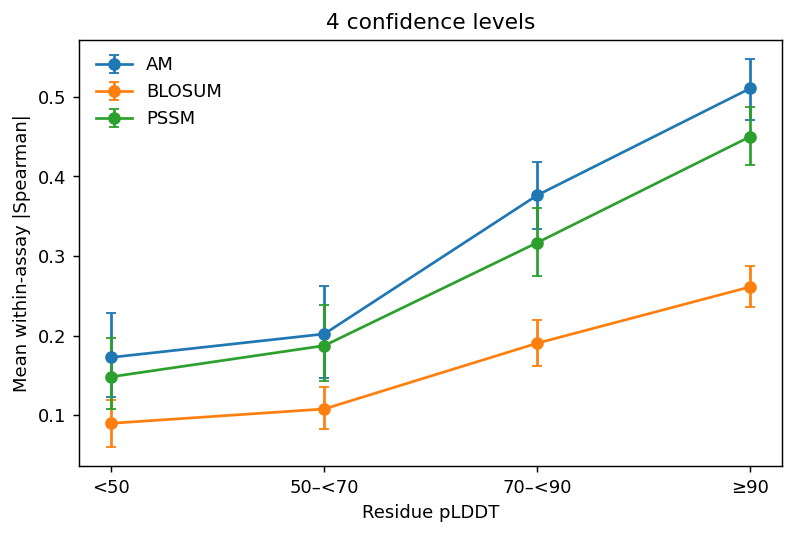

,scheme,method,level,mean,low,high,n_assays
0,4 confidence levels,AM,0,0.172611,0.122314,0.228136,29
1,4 confidence levels,AM,1,0.202027,0.146434,0.262819,44
2,4 confidence levels,AM,2,0.376436,0.333593,0.418609,61
3,4 confidence levels,AM,3,0.510761,0.471558,0.547613,59
4,4 confidence levels,BLOSUM,0,0.089702,0.060228,0.119500,29
5,4 confidence levels,BLOSUM,1,0.107737,0.082692,0.135040,44
6,4 confidence levels,BLOSUM,2,0.190402,0.161570,0.219937,61
7,4 confidence levels,BLOSUM,3,0.261261,0.236405,0.286938,59
8,4 confidence levels,PSSM,0,0.148186,0.107733,0.196754,29
9,4 confidence levels,PSSM,1,0.187340,0.142673,0.238314,44


,subset,scheme,comparison,mean,low,high,n_assays,wilcoxon_p
0,All,4 confidence levels,AM,0.323066,0.229376,0.405641,27,1.311302e-06
1,All,4 confidence levels,BLOSUM,0.163759,0.121958,0.205590,27,2.041459e-06
2,All,4 confidence levels,PSSM,0.274841,0.208517,0.334981,27,7.450581e-08
3,All,4 confidence levels,AM minus BLOSUM,0.159307,0.086280,0.230185,27,3.807098e-04
4,All,4 confidence levels,AM minus PSSM,0.048225,-0.017431,0.112941,27,9.056485e-02
5,Discovery,4 confidence levels,AM,0.225653,0.094066,0.363469,11,1.367188e-02
6,Discovery,4 confidence levels,BLOSUM,0.123106,0.052893,0.186649,11,1.855469e-02
7,Discovery,4 confidence levels,PSSM,0.255968,0.161056,0.363196,11,2.929688e-03
8,Discovery,4 confidence levels,AM minus BLOSUM,0.102547,0.005029,0.205234,11,8.300781e-02
9,Discovery,4 confidence levels,AM minus PSSM,-0.030314,-0.146526,0.085659,11,6.376953e-01


scheme               level
4 confidence levels  0             0.596501
                     1             1.229026
                     2        372489.443512
                     3        252557.541307
Name: DMS dynamic range, dtype: float64

In [10]:
def bootstrap_mean(values,seed=11,repeats=2000):
    values=np.asarray(values,dtype=float);values=values[np.isfinite(values)]
    if len(values)==0:return np.nan,np.nan,np.nan,0
    rng=np.random.default_rng(seed)
    samples=values[rng.integers(0,len(values),(repeats,len(values)))].mean(axis=1)
    low,high=np.quantile(samples,[.025,.975])
    return values.mean(),low,high,len(values)

curve_rows=[]
fig,axes=plt.subplots(1,scores.scheme.nunique(),figsize=(6*scores.scheme.nunique(),4),squeeze=False,constrained_layout=True)
for ax,(scheme,group) in zip(axes.ravel(),scores.groupby('scheme',sort=True)):
    for method in ['AM','BLOSUM','PSSM']:
        points=[]
        for level,cell in group.groupby('level'):
            mean,low,high,count=bootstrap_mean(cell[method],seed=0 if RUN==1 else 11,repeats=5000 if RUN==1 else 2000)
            record=dict(scheme=scheme,method=method,level=level,mean=mean,low=low,high=high,n_assays=count)
            points.append(record);curve_rows.append(record)
        points=pd.DataFrame(points)
        ax.errorbar(points.level,points['mean'],yerr=[points['mean']-points.low,points.high-points['mean']],marker='o',capsize=3,label=method)
    levels=sorted(group.level.unique())
    ax.set(xticks=levels,xticklabels=LEVEL_LABELS[scheme],xlabel=AXIS_LABEL,ylabel='Mean within-assay |Spearman|',title=scheme)
    ax.legend(frameon=False)
show_figure(fig)
curves=pd.DataFrame(curve_rows);curves.to_csv(OUT/'curves.csv',index=False)
display(curves)

def paired_effects(table,label):
    result=[]
    for scheme,group in table.groupby('scheme'):
        pivots={method:group.pivot(index='assay',columns='level',values=method) for method in ['AM','BLOSUM','PSSM']}
        low=min(scores.loc[scores.scheme==scheme,'level']);high=max(scores.loc[scores.scheme==scheme,'level'])
        common=None
        for pivot in pivots.values():
            eligible=set(pivot.reindex(columns=[low,high]).dropna().index)
            common=eligible if common is None else common & eligible
        ids=sorted(common or [])
        delta={method:(pivot.reindex(index=ids,columns=[low,high])[high]-pivot.reindex(index=ids,columns=[low,high])[low]).to_numpy() for method,pivot in pivots.items()}
        comparisons={**delta,'AM minus BLOSUM':delta['AM']-delta['BLOSUM'],'AM minus PSSM':delta['AM']-delta['PSSM']}
        for comparison,values in comparisons.items():
            mean,lo,hi,count=bootstrap_mean(values,seed=0 if RUN==1 else 11,repeats=5000 if RUN==1 else 2000)
            p=float(wilcoxon(values).pvalue) if count and np.any(values!=0) else np.nan
            result.append(dict(subset=label,scheme=scheme,comparison=comparison,mean=mean,low=lo,high=hi,n_assays=count,wilcoxon_p=p))
    return result

effects=[]
for label,table in [('All',scores),('Discovery',scores[scores.split=='discovery']),('Confirmation',scores[scores.split=='confirmation']),('Excluding stability',scores[scores.selection!='Stability'])]:
    effects.extend(paired_effects(table,label))
if RUN==1:effects.extend(paired_effects(scores[scores.total_hits>=30],'At least 30 homologs'))
effects=pd.DataFrame(effects);effects.to_csv(OUT/'paired_effects.csv',index=False)
display(effects)
display(scores.groupby(['scheme','level']).dms_std.mean().rename('DMS dynamic range'))


Separate alignment support from structural confidence and assay dynamic range by binning within assay, centering each variable within assay, and fitting the displayed ordinary least-squares model. Both coverage-based and confidence-based bins are evaluated.


In [11]:
def adjusted_control(binby):
    rows=[]
    for assay,group in variants.dropna(subset=['coverage','plddt']).groupby('assay'):
        group=group.copy()
        group['cell']=pd.qcut(group[binby],6,labels=False,duplicates='drop')
        for cell,subset in group.groupby('cell'):
            rows.append(dict(assay=assay,am=agreement(subset,'am_pathogenicity'),coverage=subset.coverage.mean(),plddt=subset.plddt.mean(),log_dms_sd=np.log(subset.DMS_score.std()+1e-9)))
    cells=pd.DataFrame(rows).replace([np.inf,-np.inf],np.nan).dropna()
    columns=['coverage','plddt','log_dms_sd']
    for column in ['am']+columns:cells[column+'_centered']=cells[column]-cells.groupby('assay')[column].transform('mean')
    x=np.column_stack([np.ones(len(cells))]+[cells[column+'_centered'] for column in columns]);y=cells.am_centered.to_numpy()
    beta=np.linalg.lstsq(x,y,rcond=None)[0];residual=y-x@beta
    rank=np.linalg.matrix_rank(x)
    se=np.sqrt(np.diag((residual@residual)/max(len(cells)-rank,1)*np.linalg.pinv(x.T@x)))
    cells.to_csv(OUT/f'control_cells_{binby}.csv',index=False)
    return [dict(binning=binby,covariate=column,beta=beta[i+1],standard_error=se[i+1],t=beta[i+1]/se[i+1],cells=len(cells),rank=rank) for i,column in enumerate(columns)]
adjusted=pd.DataFrame(adjusted_control('coverage')+adjusted_control('plddt'))
adjusted.to_csv(OUT/'adjusted_controls.csv',index=False);display(adjusted)


,binning,covariate,beta,standard_error,t,cells,rank
0,coverage,coverage,0.066293,0.040337,1.643480,377,4
1,coverage,plddt,0.004519,0.000953,4.742275,377,4
2,coverage,log_dms_sd,0.158974,0.035824,4.437683,377,4
3,plddt,coverage,0.069214,0.057245,1.209093,378,4
4,plddt,plddt,0.004624,0.000758,6.102799,378,4
5,plddt,log_dms_sd,0.186934,0.033341,5.606659,378,4


## 6. Decision and reason


In [12]:
MAIN_SCHEME='4 confidence levels'

selected=effects[(effects.scheme==MAIN_SCHEME)&(effects.comparison=='AM')]
pooled=selected.loc[selected.subset=='All'].iloc[0]
confirmation=selected.loc[selected.subset=='Confirmation'].iloc[0]
supported=pooled.low>0 and confirmation['mean']>0
decision='Accept the axis–performance association' if supported else 'Reject the axis as a supported positive association'
if RUN==2 and AXIS==3:
    decision='Retain alignment support as a control; do not accept a separate independent axis'
display(Markdown(f'**{decision}.** The paired high-minus-low AlphaMissense effect is {pooled["mean"]:.3f} (95% interval {pooled.low:.3f} to {pooled.high:.3f}; {int(pooled.n_assays)} assays). The confirmation effect is {confirmation["mean"]:.3f}.'))
baseline=effects[(effects.subset=='All')&(effects.scheme==MAIN_SCHEME)&effects.comparison.isin(['AM minus BLOSUM','AM minus PSSM'])]
display(baseline)
for row in baseline.itertuples(index=False):
    assessment='a positive difference beyond this reference' if row.low>0 else 'no established positive difference beyond this reference'
    display(Markdown(f'{row.comparison}: {row.mean:.3f} (95% interval {row.low:.3f} to {row.high:.3f}); {assessment}.'))
if RUN==2 and AXIS==3:
    display(Markdown('Coverage and pLDDT vary together. The adjusted controls above determine how much association remains after structural confidence and experimental dynamic range are included; this control analysis does not establish a separate causal mechanism.'))


**Accept the axis–performance association.** The paired high-minus-low AlphaMissense effect is 0.323 (95% interval 0.229 to 0.406; 27 assays). The confirmation effect is 0.390.

,subset,scheme,comparison,mean,low,high,n_assays,wilcoxon_p
3,All,4 confidence levels,AM minus BLOSUM,0.159307,0.086280,0.230185,27,0.000381
4,All,4 confidence levels,AM minus PSSM,0.048225,-0.017431,0.112941,27,0.090565


AM minus BLOSUM: 0.159 (95% interval 0.086 to 0.230); a positive difference beyond this reference.

AM minus PSSM: 0.048 (95% interval -0.017 to 0.113); no established positive difference beyond this reference.

In [13]:
files=[dict(path=str(path.relative_to(OUT)),bytes=path.stat().st_size,sha256=sha256(path)) for path in sorted(OUT.iterdir()) if path.is_file() and path.name!='OUTPUT_MANIFEST.json']
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(files,indent=2)+'\n')
print('Outputs:',str(OUT.resolve()))


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/alphamissense/am-opus-r2/am-opus-r2-test-01-outputs
